# Samvidhan Saathi
### Retrieval-Augmented Question Answering over the Constitution of India

**UCS748 – Generative AI** · Thapar Institute of Engineering & Technology

| Name | Roll No. |
|---|---|
| Parth Verma | 102495001 |
| Dhruv Garg | 102315282 |
| Abhiranjan Sinha | 102315263 |
| Harshdeep Jhakar | 102315269 |

A RAG system that answers questions about the Constitution of India from the constitutional text, citing the Articles it uses.
The notebook builds the pipeline end to end, compares two generator sizes, and fine-tunes the retriever on domain data.

**Pipeline:** PDF → cleaning → Article-level chunking → BGE embeddings → FAISS → similarity guardrail → Qwen2.5 (grounded generation) → citation check

## 1. Setup

In [1]:
!pip install -q pypdf faiss-cpu sentence-transformers datasets accelerate gradio

import os, re, math, time, random, warnings
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
import faiss
import matplotlib.pyplot as plt
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM
warnings.filterwarnings("ignore", category=DeprecationWarning)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

CONFIG = {
    "pdf_path":            "constitution_of_india.pdf",
    "embed_model":         "BAAI/bge-small-en-v1.5",
    "generators":          {"Qwen2.5-1.5B": "Qwen/Qwen2.5-1.5B-Instruct",
                            "Qwen2.5-3B":   "Qwen/Qwen2.5-3B-Instruct"},
    "fixed_chunk_size":    1000,    # characters (baseline chunking)
    "fixed_chunk_overlap": 150,
    "max_chunk_chars":     1500,    # keeps every chunk within the encoder's 512-token limit
    "top_k":               3,       # distinct Articles passed to the generator
    "eval_k":              5,       # retrieval depth for Hit@k / MRR
    "max_new_tokens":      350,
    "ft_epochs":           3,
    "ft_batch_size":       32,
    "ft_learning_rate":    2e-5,
    "ft_warmup_fraction":  0.1,
}

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def style_axes(ax, title, xlabel=None, ylabel=None, grid_axis="y", title_pad=6):
    """Shared, minimal styling for all figures."""
    ax.figure.set_facecolor("#fcfcfb")
    ax.set_facecolor("#fcfcfb")
    ax.set_title(title, loc="left", fontsize=11, color="#0b0b0b", pad=title_pad)
    if xlabel: ax.set_xlabel(xlabel, color="#52514e")
    if ylabel: ax.set_ylabel(ylabel, color="#52514e")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors="#898781")
    ax.grid(axis=grid_axis, color="#e1e0d9", lw=0.8)
    ax.set_axisbelow(True)

Device: cuda (Tesla T4)


## 2. Data Preparation
Source: *The Constitution of India (2026, English Version)*, Legislative Department, Ministry of Law & Justice.

In [2]:
# Load the PDF (upload it when prompted)
pdf_path = Path(CONFIG["pdf_path"])
if not pdf_path.exists():
    from google.colab import files
    print("Upload the Constitution of India PDF (English Version).")
    uploaded = files.upload()
    os.rename(next(iter(uploaded)), pdf_path)

raw_pages = [page.extract_text() or "" for page in PdfReader(str(pdf_path)).pages]
print(f"{pdf_path.name}: {len(raw_pages)} pages, {sum(map(len, raw_pages)):,} characters")

Upload the Constitution of India PDF (English Version).


Saving constitution_of_india.pdf to constitution_of_india.pdf
constitution_of_india.pdf: 402 pages, 861,528 characters


**Cleaning.** Rule-based removal of layout artefacts: Table of Contents, running headers, page numbers, amendment footnotes
(which can appear mid-page in the extracted text), inline amendment markers and symbol-font glyphs. Part headings are kept as metadata.

In [3]:
HEADER_RE      = re.compile(r"^\s*\d*\s*THE CONSTITUTION OF INDIA\s*\d*\s*$")
PART_HEADER_RE = re.compile(r"^\s*\(Part\s+[IVXLC]+[A-Z]?\.?\s*—.*\)\s*$")
PAGE_NUM_RE    = re.compile(r"^\s*\d{1,3}\s*$")
FOOTNOTE_RE    = re.compile(r"^\s*1\.\s+(?!.*\.\s*—)\S")   # "1. Subs. by…" but not "1. Name….—"
PART_RE        = re.compile(r"^\s*PART\s+([IVXLC]+[A-Z]?)\s*$")
SMALL_WORDS    = {"and", "of", "the", "in", "to", "its", "for", "or", "on", "under", "with"}


def is_heading(line: str) -> bool:
    letters = re.sub(r"[^A-Za-z]", "", line)
    return len(letters) >= 4 and letters.isupper()


def to_title_case(text: str) -> str:
    words = text.lower().split()
    return " ".join(w if (i and w in SMALL_WORDS) else w.capitalize() for i, w in enumerate(words))


def locate_body(pages: list[str]) -> tuple[int, int]:
    """First and last page of the Articles; the em-dash separates body headings from ToC entries."""
    flat = [re.sub(r"\s+", " ", p) for p in pages]
    start = next(i for i, p in enumerate(flat) if re.search(r"\b1\.\s+Name and territory of the Union\.\s*—", p))
    end   = next(i for i, p in enumerate(flat) if re.search(r"\b395\.\s+Repeals\.\s*—", p))
    return start, end


def strip_markers(line: str) -> str:
    """Remove amendment markers ('2[21A.' → '21A.', '1***' → ''), brackets and symbol-font glyphs."""
    line = re.sub(r"[-]", "", line)
    line = re.sub(r"(?<![\w.])\d{1,2}\[", "[", line)
    line = re.sub(r"\d*\*{3,}", "", line)
    line = line.replace("[", "").replace("]", "")
    return re.sub(r"\s+", " ", line).strip()


def remove_footnotes(lines: list[str], stats: Counter) -> list[str]:
    """Drop footnote blocks: '1.', '2.', … entries and their continuations, until the sequence breaks."""
    out, i = [], 0
    while i < len(lines):
        if not FOOTNOTE_RE.match(lines[i]):
            out.append(lines[i]); i += 1
            continue
        expected, closed = 1, True
        while i < len(lines):
            line = lines[i].strip()
            if not line:
                i += 1; continue
            if re.match(rf"^{expected}\.\s+(?!.*\.\s*—)", line):
                expected += 1
            elif closed:
                break
            stats["footnote_lines"] += 1
            closed = line.endswith(".")
            i += 1
    return out


def clean_page(text: str, stats: Counter) -> list[str]:
    lines = [strip_markers(l) for l in remove_footnotes(text.split("\n"), stats)]
    cleaned, i = [], 0
    while i < len(lines):
        line = lines[i]
        if not line:
            i += 1; continue
        if HEADER_RE.match(line) or PART_HEADER_RE.match(line):
            stats["header_lines"] += 1; i += 1; continue
        if PAGE_NUM_RE.match(line):
            stats["page_numbers"] += 1; i += 1; continue
        m = PART_RE.match(line)
        if m:                                   # Part heading → structured marker
            title, j = [], i + 1
            while j < len(lines) and (not lines[j] or
                  (is_heading(lines[j]) and not lines[j].startswith("CHAPTER"))):
                if lines[j]:
                    title.append(lines[j])
                j += 1
            cleaned.append(f"§PART|{m.group(1)}|{to_title_case(' '.join(title))}")
            stats["part_headings"] += 1; i = j; continue
        if is_heading(line):
            stats["other_headings"] += 1; i += 1; continue
        cleaned.append(line)
        i += 1
    return cleaned


stats = Counter()
body_start, body_end = locate_body(raw_pages)
clean_pages = [(p, clean_page(raw_pages[p], stats)) for p in range(body_start, body_end + 1)]

raw_chars   = sum(len(raw_pages[p]) for p in range(body_start, body_end + 1))
clean_chars = sum(len(" ".join(l)) for _, l in clean_pages)
print(f"Body pages {body_start}–{body_end} ({body_start} front-matter pages skipped)")
print(f"Removed: {stats['footnote_lines']} footnote lines, {stats['header_lines']} header lines, "
      f"{stats['page_numbers']} page numbers, {stats['other_headings']} headings")
print(f"Part headings captured: {stats['part_headings']}")
print(f"Characters: {raw_chars:,} → {clean_chars:,} ({100 * (1 - clean_chars / raw_chars):.1f}% noise removed)")

Body pages 32–282 (32 front-matter pages skipped)
Removed: 845 footnote lines, 450 header lines, 26 page numbers, 28 headings
Part headings captured: 26
Characters: 587,637 → 502,148 (14.5% noise removed)


**Structure-aware chunking.** Each Article becomes one chunk carrying its Part and section. Articles longer than the encoder limit
are split at clause boundaries, and every segment keeps the Article header. Coverage of Articles 1–395 is checked automatically.

In [4]:
ARTICLE_RE       = re.compile(r"^(\d{1,3}[A-Z]{0,3})\.\s+([^—]{3,300}?)\.\s*—\s*(.*)$", re.S)
ARTICLE_START_RE = re.compile(r"^\d{1,3}[A-Z]{0,3}\.\s")
TERMINAL         = tuple(".;:,—)")
MAX_GAP          = 10       # Article numbers must increase monotonically
KNOWN_REPEALED   = {238}    # Part VII (sole Article 238) repealed by the 7th Amendment, 1956


def base_number(article: str) -> int:
    return int(re.match(r"\d+", article).group())


def is_subheading(line: str) -> bool:
    return (line[:1].isupper() and not line.endswith(TERMINAL)
            and len(line.split()) <= 8 and not line.startswith("§"))


def segment_articles(clean_pages: list) -> tuple[list[dict], dict]:
    flat = [(p, line) for p, lines in clean_pages for line in lines]
    records, buffer, current = [], [], None
    part, section, last_base, skip = None, None, 0, 0
    seg_stats = {"rejected": 0, "omitted": []}

    def close():
        if current is None:
            return
        body = re.sub(r"\s+", " ", " ".join([current.pop("first")] + buffer)).strip()
        if body.lower().startswith("omitted") and len(body) < 400:
            seg_stats["omitted"].append(current["article"])
        else:
            records.append({**current, "body": body})

    for i, (page, line) in enumerate(flat):
        if line.startswith("§PART|"):
            _, num, title = line.split("|", 2)
            part, section = f"Part {num} – {title}", None
            continue
        m = None
        if ARTICLE_START_RE.match(line):
            window = " ".join(l for _, l in flat[i:i + 3] if not l.startswith("§"))
            m = ARTICLE_RE.match(window)
            if m and not (last_base <= base_number(m.group(1)) <= last_base + MAX_GAP):
                seg_stats["rejected"] += 1
                m = None
        if m:
            while buffer and is_subheading(buffer[-1]):
                section = buffer.pop()
            close()
            num, title = m.group(1), re.sub(r"\s+", " ", m.group(2)).strip(" .")
            last_base = base_number(num)
            current = {"article": num, "title": title, "part": part,
                       "section": section, "pdf_page": page + 1, "first": ""}
            buffer, skip = [], 0
            if "—" in line:
                current["first"] = line.split("—", 1)[1]
            else:                                   # title wraps onto the next line(s)
                for _, nxt in flat[i + 1:i + 3]:
                    skip += 1
                    if "—" in nxt:
                        current["first"] = nxt.split("—", 1)[1]
                        break
            continue
        if current is not None:
            if skip:
                skip -= 1
                continue
            buffer.append(line)
    close()
    return records, seg_stats


def split_long(text: str, max_chars: int) -> list[str]:
    """Split on clause boundaries '(1)', '(2)'…, then sentences; pack greedily."""
    if len(text) <= max_chars:
        return [text]
    units = []
    for clause in re.split(r"\s(?=\(\d+[A-Z]?\)\s)", text):
        if len(clause) <= max_chars:
            units.append(clause)
            continue
        for sent in re.split(r"(?<=[.;:])\s+", clause):
            while len(sent) > max_chars:
                cut = sent.rfind(" ", 0, max_chars)
                units.append(sent[:cut]); sent = sent[cut + 1:]
            units.append(sent)
    chunks, cur = [], ""
    for u in units:
        if cur and len(cur) + 1 + len(u) > max_chars:
            chunks.append(cur); cur = u
        else:
            cur = f"{cur} {u}".strip()
    return chunks + ([cur] if cur else [])


def extract_preamble(pages: list[str], body_start: int):
    for p in range(body_start - 1, -1, -1):
        m = re.search(r"WE,\s*THE\s+PEOPLE\s+OF\s+INDIA.*?THIS\s+CONSTITUTION\.", pages[p], re.S)
        if m:
            return p, strip_markers(m.group(0))
    return None, None


records, seg_stats = segment_articles(clean_pages)
pre_page, pre_text = extract_preamble(raw_pages, body_start)
if pre_text:
    records.insert(0, {"article": "Preamble", "title": "Preamble", "part": "Preamble",
                       "section": None, "pdf_page": pre_page + 1, "body": pre_text})

chunks = []
for r in records:
    header = r["title"] if r["article"] == "Preamble" else f"Article {r['article']} – {r['title']}"
    segments = split_long(r["body"], CONFIG["max_chunk_chars"] - len(header) - 20)
    for k, seg in enumerate(segments, 1):
        label = header if len(segments) == 1 else f"{header} (segment {k}/{len(segments)})"
        chunks.append({"chunk_id": len(chunks), "article": r["article"], "title": r["title"],
                       "part": r["part"], "section": r["section"], "pdf_page": r["pdf_page"],
                       "segment": k, "n_segments": len(segments), "text": f"{label}\n{seg}"})
chunks_df = pd.DataFrame(chunks)

present = {base_number(r["article"]) for r in records if r["article"] != "Preamble"}
omitted = {base_number(a) for a in seg_stats["omitted"]}
missing = sorted(set(range(1, 396)) - present - omitted - KNOWN_REPEALED)

print(f"Articles parsed: {len(records) - bool(pre_text)} (+ Preamble) | omitted Articles skipped: {len(seg_stats['omitted'])}")
print(f"Coverage of Articles 1–395: {395 - len(missing)}/395" + (f" | missing {missing}" if missing else " ✓"))
print(f"Chunks: {len(chunks_df)} | long Articles split: {chunks_df.loc[chunks_df.n_segments > 1, 'article'].nunique()} "
      f"| max chunk {chunks_df.text.str.len().max()} chars")
display(chunks_df[chunks_df.article.isin(["Preamble", "14", "21", "21A", "51A"])]
        [["article", "title", "part", "section", "pdf_page"]].reset_index(drop=True))

Articles parsed: 467 (+ Preamble) | omitted Articles skipped: 28
Coverage of Articles 1–395: 395/395 ✓
Chunks: 613 | long Articles split: 82 | max chunk 1494 chars


,article,title,part,section,pdf_page
0,Preamble,Preamble,Preamble,None,32
1,14,Equality before law,Part III – Fundamental Rights,Right to Equality,37
2,21,Protection of life and personal liberty,Part III – Fundamental Rights,Right to Freedom,42
3,21A,Right to education,Part III – Fundamental Rights,Right to Freedom,42
4,51A,Fundamental duties,Part IVA – Fundamental Duties,None,56


## 3. Retrieval
Baseline: the same cleaned text re-chunked into fixed 1000-character windows. Both chunk sets are embedded with
`bge-small-en-v1.5` (384-d, unit-normalised) and indexed with FAISS `IndexFlatIP` (exact cosine search).

In [5]:
def build_document_with_spans(records: list[dict]) -> tuple[str, list[tuple]]:
    """Cleaned text in reading order, with each Article's character span (ground truth for the baseline)."""
    parts, spans, pos = [], [], 0
    for r in records:
        block = (f"{r['title']}. {r['body']}" if r["article"] == "Preamble"
                 else f"{r['article']}. {r['title']}.—{r['body']}")
        spans.append((r["article"], pos, pos + len(block)))
        parts.append(block)
        pos += len(block) + 1
    return " ".join(parts), spans


def fixed_size_chunks(text: str, size: int, overlap: int) -> list[tuple[int, int]]:
    windows, start = [], 0
    while start < len(text):
        end = min(start + size, len(text))
        if end < len(text):
            space = text.rfind(" ", start, end)
            if space > start + size // 2:
                end = space
        windows.append((start, end))
        if end == len(text):
            break
        start = end - overlap
        nxt = text.find(" ", start, end)
        start = nxt + 1 if nxt != -1 else start
    return windows


document, article_spans = build_document_with_spans(records)
windows  = fixed_size_chunks(document, CONFIG["fixed_chunk_size"], CONFIG["fixed_chunk_overlap"])
fixed_df = pd.DataFrame([{"chunk_id": i, "text": document[s:e],
                          "articles": [a for a, a_s, a_e in article_spans if a_s < e and a_e > s]}
                         for i, (s, e) in enumerate(windows)])

QUERY_PREFIX  = "Represent this sentence for searching relevant passages: "   # BGE query instruction
embedder_base = SentenceTransformer(CONFIG["embed_model"], device=DEVICE)


def build_index(model: SentenceTransformer, texts: list[str]) -> faiss.Index:
    vecs = model.encode(texts, batch_size=64, normalize_embeddings=True,
                        convert_to_numpy=True, show_progress_bar=False).astype("float32")
    index = faiss.IndexFlatIP(vecs.shape[1])
    index.add(vecs)
    return index


# retriever name → (embedding model, index, chunk table)
RETRIEVERS = {
    "fixed": (embedder_base, build_index(embedder_base, fixed_df.text.tolist()), fixed_df),
    "base":  (embedder_base, build_index(embedder_base, chunks_df.text.tolist()), chunks_df),
}


def retrieve(query: str, retriever: str, k: int) -> pd.DataFrame:
    model, index, df = RETRIEVERS[retriever]
    q = model.encode([QUERY_PREFIX + query], normalize_embeddings=True).astype("float32")
    scores, ids = index.search(q, k)
    hits = df.iloc[ids[0]].copy()
    hits["score"] = scores[0]
    return hits.reset_index(drop=True)


tok_lens  = [len(embedder_base.tokenizer(t)["input_ids"]) for t in chunks_df.text]
not_whole = sum(1 for _, a_s, a_e in article_spans if not any(s <= a_s and a_e <= e for s, e in windows))
print(f"Article-level chunks: {len(chunks_df)} | max {max(tok_lens)} tokens "
      f"(limit {embedder_base.max_seq_length}) → truncated: {sum(l > embedder_base.max_seq_length for l in tok_lens)}")
print(f"Fixed-size chunks:    {len(fixed_df)} | {fixed_df.articles.str.len().mean():.2f} Articles per chunk | "
      f"{not_whole}/{len(article_spans)} Articles not contained whole in any chunk")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Article-level chunks: 613 | max 355 tokens (limit 512) → truncated: 0
Fixed-size chunks:    584 | 1.93 Articles per chunk | 307/468 Articles not contained whole in any chunk


## 4. Evaluation Sets
35 plain-language questions with gold Articles (held out from all tuning), plus 10 in-domain and 10 out-of-domain questions
for calibrating the refusal threshold. A fixed-size chunk counts as relevant if it overlaps any part of a gold Article,
a criterion that favours the baseline.

In [6]:
EVAL_SET = [
    ("Are all people equal in the eyes of the law?",                                  {"14"}),
    ("Can the State discriminate against someone because of their caste or religion?", {"15"}),
    ("Do all citizens get an equal chance in government jobs?",                       {"16"}),
    ("Can the government give people titles like 'Sir' or 'Rai Bahadur'?",            {"18"}),
    ("Do I have the right to hold a peaceful protest without weapons?",               {"19"}),
    ("Can a new law punish me for something that was legal when I did it?",           {"20"}),
    ("Is education a fundamental right for children?",                                {"21A"}),
    ("Is human trafficking or forced labour prohibited?",                             {"23"}),
    ("Can religious minorities run their own schools and colleges?",                  {"30"}),
    ("Can I go directly to the Supreme Court if my fundamental rights are violated?", {"32"}),
    ("Should the State provide free legal aid to poor people?",                       {"39A"}),
    ("Is the State supposed to work towards a uniform civil code?",                   {"44"}),
    ("Should the judiciary be kept separate from the executive?",                     {"50"}),
    ("Who is the supreme commander of the armed forces?",                             {"53"}),
    ("How is the President of India elected?",                                        {"54", "55"}),
    ("How can the President be removed from office?",                                 {"61"}),
    ("Can the President pardon a person sentenced to death?",                         {"72"}),
    ("Who appoints the Prime Minister?",                                              {"75"}),
    ("Who gives legal advice to the Government of India?",                            {"76"}),
    ("How long does the Lok Sabha last before fresh elections?",                      {"83"}),
    ("Who presides over the Rajya Sabha?",                                            {"89"}),
    ("Can an MP be prosecuted for something said in Parliament?",                     {"105"}),
    ("What makes a bill a money bill?",                                               {"110"}),
    ("Does a bill passed by Parliament need the President's approval?",               {"111"}),
    ("Can the President ask the Supreme Court for its opinion on a legal question?",  {"143"}),
    ("Who audits the accounts of the Union government?",                              {"148", "149", "150", "151"}),
    ("Who appoints the Governor of a state?",                                         {"155"}),
    ("Can a High Court issue writs such as habeas corpus?",                           {"226"}),
    ("Can Parliament make laws on State List subjects in the national interest?",     {"249"}),
    ("Who conducts elections in India?",                                              {"324"}),
    ("At what age can a citizen vote?",                                               {"326"}),
    ("Can the President take over a state's government if its machinery fails?",      {"356"}),
    ("Can the government take away someone's property without a law?",               {"300A"}),
    ("Are seats reserved for Scheduled Castes in the Lok Sabha?",                     {"330"}),
    ("Does the Constitution require panchayats to be set up in villages?",            {"243B", "243"}),
]
CALIB_IN = [
    "Is there a minimum age for becoming the President?",
    "Can a person be punished twice for the same crime?",
    "Who appoints the judges of the Supreme Court?",
    "Can the government declare an emergency during a war?",
    "Is untouchability banned in India?",
    "How is the Chief Minister of a state appointed?",
    "What is the official language of the Union?",
    "Can children be employed in factories?",
    "How can the Constitution be amended?",
    "Do citizens have a duty to protect the environment?",
]
CALIB_OUT = [
    "Who won the IPL in 2024?",
    "How do I make paneer butter masala?",
    "What is the capital of Australia?",
    "Write a Python function to reverse a list.",
    "What will the weather be like in Patiala tomorrow?",
    "Which is the best smartphone under 20000 rupees?",
    "Explain photosynthesis in plants.",
    "Who directed the movie Sholay?",
    "How does backpropagation train a neural network?",
    "What is the price of gold today?",
]
HELD_OUT_QUESTIONS = {q for q, _ in EVAL_SET} | set(CALIB_IN) | set(CALIB_OUT)
RETRIEVER_NAMES = {"fixed": "Fixed-size chunking (baseline)",
                   "base":  "Structure-aware chunking",
                   "ft":    "Structure-aware + fine-tuned embedder"}


def evaluate_retrieval(retriever: str) -> pd.DataFrame:
    """Rank of the first relevant chunk (None if outside the top eval_k) for every question."""
    rows = []
    for question, gold in EVAL_SET:
        hits = retrieve(question, retriever, CONFIG["eval_k"])
        found = ([bool(set(a) & gold) for a in hits.articles] if retriever == "fixed"
                 else [a in gold for a in hits.article])
        rows.append({"question": question, "gold": ", ".join(sorted(gold)),
                     "rank": next((i + 1 for i, f in enumerate(found) if f), None)})
    return pd.DataFrame(rows)


def summarise(df: pd.DataFrame) -> pd.Series:
    r = df["rank"]
    return pd.Series({"Hit@1": (r <= 1).mean(), "Hit@3": (r <= 3).mean(),
                      "Hit@5": (r <= 5).mean(), "MRR@5": r.rdiv(1).fillna(0).mean()})


def calibrate_threshold(retriever: str) -> dict:
    """Threshold that best separates in-domain from out-of-domain top-1 similarities."""
    pos = np.array([retrieve(q, retriever, 1).score[0] for q in CALIB_IN])
    neg = np.array([retrieve(q, retriever, 1).score[0] for q in CALIB_OUT])
    cands = np.sort(np.concatenate([pos, neg]))
    mids  = (cands[:-1] + cands[1:]) / 2
    acc   = np.array([((pos >= t).sum() + (neg < t).sum()) / (len(pos) + len(neg)) for t in mids])
    return {"threshold": round(float(np.median(mids[acc == acc.max()])), 2),
            "accuracy": float(acc.max()), "pos": pos, "neg": neg}

## 5. Retrieval Results: Chunking Strategy

                                Hit@1  Hit@3  Hit@5  MRR@5
Fixed-size chunking (baseline)  0.514  0.743  0.886  0.645
Structure-aware chunking        0.657  0.829  0.857  0.740

Refusal threshold: 0.61  (in-domain min 0.690, out-of-domain max 0.536, separation 100%)


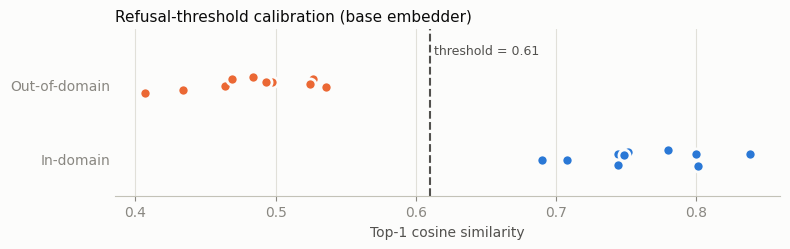

In [7]:
retrieval_runs = {r: evaluate_retrieval(r) for r in ("fixed", "base")}
print(pd.DataFrame({RETRIEVER_NAMES[r]: summarise(df) for r, df in retrieval_runs.items()}).T.round(3).to_string())

CALIBRATION = {"base": calibrate_threshold("base")}
THRESHOLDS  = {"base": CALIBRATION["base"]["threshold"]}
c = CALIBRATION["base"]
print(f"\nRefusal threshold: {THRESHOLDS['base']}  (in-domain min {c['pos'].min():.3f}, "
      f"out-of-domain max {c['neg'].max():.3f}, separation {c['accuracy']:.0%})")

fig, ax = plt.subplots(figsize=(8, 2.6))
rng = np.random.default_rng(SEED)
for y, (vals, colour) in enumerate([(c["pos"], BLUE), (c["neg"], ORANGE)]):
    ax.scatter(vals, y + rng.uniform(-0.12, 0.12, len(vals)), s=64, color=colour,
               edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.axvline(THRESHOLDS["base"], color="#52514e", ls="--", lw=1.5)
ax.text(THRESHOLDS["base"], 1.42, f" threshold = {THRESHOLDS['base']:.2f}", fontsize=9, color="#52514e")
ax.set_yticks([0, 1], ["In-domain", "Out-of-domain"], color="#0b0b0b")
ax.set_ylim(-0.5, 1.75)
style_axes(ax, "Refusal-threshold calibration (base embedder)", xlabel="Top-1 cosine similarity", grid_axis="x")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Grounded Generation
Two instruction-tuned decoders, `Qwen2.5-1.5B-Instruct` and `Qwen2.5-3B-Instruct` (float16). The prompt holds the top-3 distinct
Articles and restricts the model to them; questions below the similarity threshold are refused without calling the LLM;
cited Articles are verified against the retrieved context. Decoding is greedy, so runs are deterministic.

In [8]:
GENERATORS = {}
for name, path in CONFIG["generators"].items():
    tok = AutoTokenizer.from_pretrained(path, padding_side="left")
    llm = AutoModelForCausalLM.from_pretrained(path, dtype=torch.float16, device_map="auto").eval()
    GENERATORS[name] = (tok, llm)
    print(f"{name}: {sum(p.numel() for p in llm.parameters()) / 1e9:.2f}B parameters")
print(f"GPU memory allocated: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

SYSTEM_PROMPT = """You are Samvidhan Saathi, an assistant that answers questions about the Constitution of India.
Follow these rules strictly:
1. Answer ONLY from the constitutional text given in the context. Do not use outside knowledge.
2. Support every statement with its Article number in square brackets, e.g. [Article 21].
3. If the context does not contain the answer, reply exactly: "The provided constitutional text does not answer this question."
4. Write in simple, plain English, in 2 to 5 sentences. Never invent Article numbers."""
REFUSAL     = "I could not find a relevant provision in the Constitution of India for this question."
CITATION_RE = re.compile(r"Article\s+(\d+[A-Z]*)|\b(Preamble)\b")


def cited_articles(text: str) -> set[str]:
    return {a or p for a, p in CITATION_RE.findall(text)}


def build_context(question: str, retriever: str) -> tuple[str, list[str], float]:
    """Top-k distinct Articles; segments of the same Article are merged."""
    k = CONFIG["top_k"]
    hits = retrieve(question, retriever, k * 3)
    blocks, articles = [], []
    for article in dict.fromkeys(hits.article):
        group = hits[hits.article == article].sort_values("segment")
        body  = " ".join(t.split("\n", 1)[1] for t in group.text)
        name  = "Preamble" if article == "Preamble" else f"Article {article} – {group.iloc[0].title}"
        blocks.append(f"[{name}]\n{body}")
        articles.append(article)
        if len(articles) == k:
            break
    return "\n\n".join(blocks), articles, float(hits.score[0])


@torch.no_grad()
def generate(generator: str, messages: list[dict]) -> str:
    tok, llm = GENERATORS[generator]
    prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    enc = tok(prompt, return_tensors="pt").to(llm.device)
    out = llm.generate(**enc, max_new_tokens=CONFIG["max_new_tokens"], do_sample=False,
                       temperature=None, top_p=None, top_k=None, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()


def answer(question: str, retriever: str, generator: str) -> dict:
    """Retrieve → guardrail → grounded generation → citation verification."""
    t0 = time.time()
    context, articles, top = build_context(question, retriever)
    if top < THRESHOLDS[retriever]:
        text, refused = REFUSAL, True
    else:
        text, refused = generate(generator, [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"}]), False
    return {"answer": text, "articles": [] if refused else articles, "top": top, "refused": refused,
            "unsupported": sorted(cited_articles(text) - set(articles)), "context": "" if refused else context,
            "latency": time.time() - t0}


def closed_book(question: str, generator: str, ask_for_article: bool = True) -> str:
    """The same LLM without retrieval."""
    q = f"{question} State which Article of the Constitution of India applies." if ask_for_article else question
    return generate(generator, [{"role": "system", "content": "You are a helpful assistant. Answer concisely."},
                                {"role": "user", "content": q}])

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

... (11 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2.5-3B: 3.09B parameters
GPU memory allocated: 9.4 GB


## 7. End-to-End Results: 1.5B vs 3B Generator
Metric: does the answer cite a gold Article? *Gold in context* measures retrieval; *cited | gold in context* isolates the generator.

In [9]:
def run_end_to_end(retriever: str | None, generator: str) -> pd.DataFrame:
    rows = []
    for question, gold in EVAL_SET:
        if retriever is None:                                # closed-book
            t0 = time.time()
            text = closed_book(question, generator)
            r = {"answer": text, "articles": [], "refused": False, "unsupported": [], "latency": time.time() - t0}
        else:
            r = answer(question, retriever, generator)
            r["articles"] = build_context(question, retriever)[1]
        rows.append({"question": question, "gold": ", ".join(sorted(gold)),
                     "gold_in_context": bool(set(r["articles"]) & gold) if retriever else np.nan,
                     "correct": bool(cited_articles(r["answer"]) & gold),
                     "unsupported": bool(r["unsupported"]), "refused": r["refused"],
                     "latency_s": r["latency"], "answer": r["answer"]})
    return pd.DataFrame(rows)


def e2e_table(runs: dict) -> pd.DataFrame:
    n = len(EVAL_SET)
    rows = {}
    for label, df in runs.items():
        in_ctx = df[df.gold_in_context == True]
        rows[label] = {
            "Gold in context":         "–" if df.gold_in_context.isna().all() else f"{int(df.gold_in_context.sum())}/{n}",
            "Correct Article cited":   f"{int(df.correct.sum())}/{n} ({df.correct.mean():.0%})",
            "Cited | gold in context": "–" if len(in_ctx) == 0 else f"{int(in_ctx.correct.sum())}/{len(in_ctx)}",
            "Unsupported citations":   "–" if df.gold_in_context.isna().all() else int(df.unsupported.sum()),
            "Refusals":                int(df.refused.sum()),
            "Latency (s)":             round(df.latency_s.mean(), 2),
        }
    return pd.DataFrame(rows).T


E2E = {}
for gen in GENERATORS:
    E2E[f"Closed-book · {gen}"] = run_end_to_end(None, gen)
for gen in GENERATORS:
    E2E[f"RAG (base retriever) · {gen}"] = run_end_to_end("base", gen)
display(e2e_table(E2E))

,Gold in context,Correct Article cited,Cited | gold in context,Unsupported citations,Refusals,Latency (s)
Closed-book · Qwen2.5-1.5B,–,9/35 (26%),–,–,0,1.59
Closed-book · Qwen2.5-3B,–,21/35 (60%),–,–,0,2.91
RAG (base retriever) · Qwen2.5-1.5B,30/35,27/35 (77%),26/30,2,1,2.6
RAG (base retriever) · Qwen2.5-3B,30/35,29/35 (83%),28/30,3,1,2.61


## 8. Fine-Tuning the Retriever
No labelled dataset exists, so `Qwen2.5-1.5B` writes two everyday-language questions for every chunk (temperature 0.7 for diversity).
Malformed questions are filtered out, and so is any question within cosine 0.90 of an evaluation or calibration question
(leakage guard). 10% of chunks are held out as a development set.

In [10]:
GEN_SYSTEM = """You write questions that ordinary Indian citizens might ask about their Constitution.
Given one provision of the Constitution of India, write TWO different questions that this provision answers.
Use simple everyday language, as a non-lawyer would ask, and the everyday names Indians commonly use for
institutions and offices rather than the formal legal wording of the text. Do not copy phrases from the text.
Do not mention Article or clause numbers. Output exactly two lines, each a single question ending with '?'."""
BANNED_RE = re.compile(r"\barticle\b|\bclause\b|\bthis (?:provision|text|passage|section)\b", re.I)


@torch.no_grad()
def generate_batch(generator: str, batch_messages: list[list[dict]], temperature: float = 0.7) -> list[str]:
    tok, llm = GENERATORS[generator]
    texts = [tok.apply_chat_template(m, tokenize=False, add_generation_prompt=True) for m in batch_messages]
    enc = tok(texts, return_tensors="pt", padding=True).to(llm.device)
    out = llm.generate(**enc, max_new_tokens=96, do_sample=True, temperature=temperature,
                       top_p=0.9, pad_token_id=tok.eos_token_id)
    return [tok.decode(o[enc["input_ids"].shape[1]:], skip_special_tokens=True) for o in out]


def parse_questions(text: str) -> list[str]:
    qs = []
    for line in text.split("\n"):
        line = re.sub(r"^\s*(?:\d+[.)]|[-*•]|Q\d*\s*[:.])\s*", "", line).strip().strip('"')
        if line.endswith("?"):
            qs.append(line)
    return qs[:2]


t0, raw = time.time(), []
for start in range(0, len(chunks_df), 16):
    batch = chunks_df.iloc[start:start + 16]
    msgs = [[{"role": "system", "content": GEN_SYSTEM},
             {"role": "user", "content": f"Provision:\n{t}\n\nWrite two questions."}] for t in batch.text]
    for (_, row), out in zip(batch.iterrows(), generate_batch("Qwen2.5-1.5B", msgs)):
        raw += [{"question": q, "chunk_id": int(row.chunk_id)} for q in parse_questions(out)]
synth = pd.DataFrame(raw)
n_raw = len(synth)

synth = synth[synth.question.apply(lambda q: 5 <= len(q.split()) <= 30 and not BANNED_RE.search(q))]
synth = synth.drop_duplicates("question")
n_formed = len(synth)
held_vecs  = embedder_base.encode(sorted(HELD_OUT_QUESTIONS), normalize_embeddings=True)
synth_vecs = embedder_base.encode(synth.question.tolist(), normalize_embeddings=True, batch_size=128)
synth = synth[((synth_vecs @ held_vecs.T).max(axis=1) <= 0.90)
              & ~synth.question.isin(HELD_OUT_QUESTIONS)].reset_index(drop=True)

dev_chunks = set(np.random.default_rng(SEED).choice(chunks_df.chunk_id.values,
                                                    size=int(0.1 * len(chunks_df)), replace=False))
train_df = synth[~synth.chunk_id.isin(dev_chunks)]
dev_df   = synth[synth.chunk_id.isin(dev_chunks)]

print(f"Generated {n_raw} questions in {(time.time() - t0) / 60:.1f} min → {n_formed} after quality filters "
      f"→ {len(synth)} after leakage guard")
print(f"Train pairs: {len(train_df)} | dev pairs: {len(dev_df)} ({len(dev_chunks)} unseen chunks)")
display(synth.merge(chunks_df[["chunk_id", "article"]]).sample(8, random_state=SEED)
        [["article", "question"]].reset_index(drop=True))

Generated 1218 questions in 2.4 min → 779 after quality filters → 777 after leakage guard
Train pairs: 702 | dev pairs: 75 (61 unseen chunks)


,article,question
0,308,Why do we need to exclude the State of Jammu a...
1,280,What does the Finance Commission do?
2,327,What must Parliament do to have fair elections?
3,65,What happens if the President dies?
4,317,What does it mean if someone involved in a gov...
5,124A,Can the government appoint judges without foll...
6,275,What happens to the money when a state becomes...
7,226,How long can a High Court wait to decide an ap...


**Contrastive fine-tuning.** `MultipleNegativesRankingLoss`: each question must score its own chunk above the other chunks in the batch.
A duplicate-free batch sampler prevents false negatives, and a low learning rate with warm-up preserves pre-trained knowledge.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Epoch,Training Loss,Validation Loss,Dev Cosine Accuracy@1,Dev Cosine Accuracy@3,Dev Cosine Accuracy@5,Dev Cosine Accuracy@10,Dev Cosine Precision@1,Dev Cosine Precision@3,Dev Cosine Precision@5,Dev Cosine Precision@10,Dev Cosine Recall@1,Dev Cosine Recall@3,Dev Cosine Recall@5,Dev Cosine Recall@10,Dev Cosine Ndcg@10,Dev Cosine Mrr@10,Dev Cosine Map@100
1,0.564274,0.236189,0.640000,0.893333,0.946667,0.960000,0.640000,0.297778,0.189333,0.096000,0.640000,0.893333,0.946667,0.960000,0.812699,0.763460,0.765472
2,0.543547,0.195312,0.640000,0.880000,0.946667,0.973333,0.640000,0.293333,0.189333,0.097333,0.640000,0.880000,0.946667,0.973333,0.814966,0.762926,0.764091
3,0.425873,0.187802,0.653333,0.893333,0.946667,0.973333,0.653333,0.297778,0.189333,0.097333,0.653333,0.893333,0.946667,0.973333,0.824495,0.775333,0.776548


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


702 pairs · 3 epochs · 66 steps · 31s
Dev set (unseen chunks):
            accuracy@1  accuracy@3  mrr@10
Base             0.507       0.853   0.676
Fine-tuned       0.653       0.893   0.775


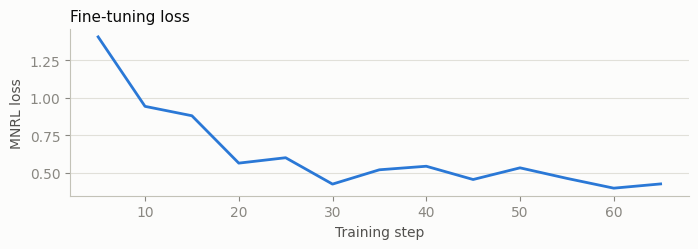

In [11]:
from datasets import Dataset
from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.losses import MultipleNegativesRankingLoss
from sentence_transformers.training_args import BatchSamplers
from sentence_transformers.evaluation import InformationRetrievalEvaluator

text_by_chunk = dict(zip(chunks_df.chunk_id, chunks_df.text))
to_pairs = lambda df: Dataset.from_dict({"anchor":   [QUERY_PREFIX + q for q in df.question],
                                         "positive": [text_by_chunk[c] for c in df.chunk_id]})
dev_evaluator = InformationRetrievalEvaluator(
    queries={f"q{i}": QUERY_PREFIX + q for i, q in enumerate(dev_df.question)},
    corpus={str(c): t for c, t in text_by_chunk.items()},
    relevant_docs={f"q{i}": {str(c)} for i, c in enumerate(dev_df.chunk_id)},
    name="dev", show_progress_bar=False)

model_ft   = SentenceTransformer(CONFIG["embed_model"], device=DEVICE)
dev_before = dev_evaluator(model_ft)
steps      = math.ceil(len(train_df) / CONFIG["ft_batch_size"]) * CONFIG["ft_epochs"]

trainer = SentenceTransformerTrainer(
    model=model_ft,
    args=SentenceTransformerTrainingArguments(
        output_dir="checkpoints", num_train_epochs=CONFIG["ft_epochs"],
        per_device_train_batch_size=CONFIG["ft_batch_size"], per_device_eval_batch_size=CONFIG["ft_batch_size"],
        learning_rate=CONFIG["ft_learning_rate"], warmup_steps=int(CONFIG["ft_warmup_fraction"] * steps),
        fp16=(DEVICE == "cuda"), batch_sampler=BatchSamplers.NO_DUPLICATES,
        eval_strategy="epoch", save_strategy="no", logging_steps=5, report_to="none", seed=SEED),
    train_dataset=to_pairs(train_df), eval_dataset=to_pairs(dev_df),
    loss=MultipleNegativesRankingLoss(model_ft), evaluator=dev_evaluator)

t0 = time.time()
trainer.train()
dev_after = dev_evaluator(model_ft)
model_ft.save("bge-small-constitution")

print(f"\n{len(train_df)} pairs · {CONFIG['ft_epochs']} epochs · {steps} steps · {time.time() - t0:.0f}s")
print("Dev set (unseen chunks):")
print(pd.DataFrame({m: [dev_before[f"dev_cosine_{m}"], dev_after[f"dev_cosine_{m}"]]
                    for m in ("accuracy@1", "accuracy@3", "mrr@10")},
                   index=["Base", "Fine-tuned"]).round(3).to_string())

log = pd.DataFrame(trainer.state.log_history)
if "loss" in log:
    loss_log = log.dropna(subset=["loss"])
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.plot(loss_log["step"], loss_log["loss"], color=BLUE, lw=2)
    style_axes(ax, "Fine-tuning loss", xlabel="Training step", ylabel="MNRL loss")
    plt.tight_layout()
    plt.show()

## 9. Retrieval Results: Fine-Tuned Embedder
The same 35 held-out questions as before. Fine-tuning shifts the similarity distribution, so the refusal threshold is re-calibrated.

                                       Hit@1  Hit@3  Hit@5  MRR@5
Fixed-size chunking (baseline)         0.514  0.743  0.886  0.645
Structure-aware chunking               0.657  0.829  0.857  0.740
Structure-aware + fine-tuned embedder  0.743  0.886  0.914  0.810

Per question vs base embedder: improved 8, worsened 3, unchanged 24
Re-calibrated threshold: 0.61 → 0.48  (in-domain min 0.563, out-of-domain max 0.406, separation 100%)


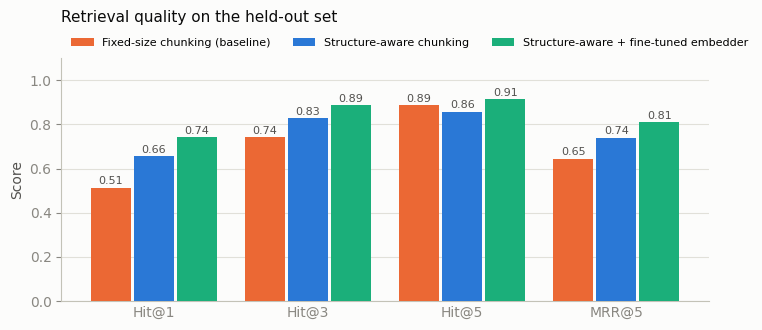

In [12]:
RETRIEVERS["ft"] = (model_ft, build_index(model_ft, chunks_df.text.tolist()), chunks_df)
retrieval_runs["ft"] = evaluate_retrieval("ft")
retrieval_table = pd.DataFrame({RETRIEVER_NAMES[r]: summarise(df) for r, df in retrieval_runs.items()}).T
print(retrieval_table.round(3).to_string())

before = retrieval_runs["base"].set_index("question")["rank"].fillna(CONFIG["eval_k"] + 1)
after  = retrieval_runs["ft"].set_index("question")["rank"].fillna(CONFIG["eval_k"] + 1)
print(f"\nPer question vs base embedder: improved {int((after < before).sum())}, "
      f"worsened {int((after > before).sum())}, unchanged {int((after == before).sum())}")

CALIBRATION["ft"] = calibrate_threshold("ft")
THRESHOLDS["ft"]  = CALIBRATION["ft"]["threshold"]
c = CALIBRATION["ft"]
print(f"Re-calibrated threshold: {THRESHOLDS['base']} → {THRESHOLDS['ft']}  (in-domain min {c['pos'].min():.3f}, "
      f"out-of-domain max {c['neg'].max():.3f}, separation {c['accuracy']:.0%})")

fig, ax = plt.subplots(figsize=(8, 3.4))
x, width = np.arange(4), 0.26
for i, (name, colour) in enumerate(zip(retrieval_table.index, [ORANGE, BLUE, AQUA])):
    vals = retrieval_table.loc[name].values
    bars = ax.bar(x + (i - 1) * (width + 0.02), vals, width, color=colour, label=name, zorder=3)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, retrieval_table.columns, color="#0b0b0b")
ax.set_ylim(0, 1.1)
style_axes(ax, "Retrieval quality on the held-out set", ylabel="Score", title_pad=26)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8)
ax.tick_params(axis="x", length=0)
plt.tight_layout()
plt.show()

## 10. Final End-to-End Results

,Gold in context,Correct Article cited,Cited | gold in context,Unsupported citations,Refusals,Latency (s)
Closed-book · Qwen2.5-1.5B,–,9/35 (26%),–,–,0,1.59
Closed-book · Qwen2.5-3B,–,21/35 (60%),–,–,0,2.91
RAG (base retriever) · Qwen2.5-1.5B,30/35,27/35 (77%),26/30,2,1,2.6
RAG (base retriever) · Qwen2.5-3B,30/35,29/35 (83%),28/30,3,1,2.61
RAG (fine-tuned retriever) · Qwen2.5-1.5B,31/35,27/35 (77%),26/31,1,2,2.73
RAG (fine-tuned retriever) · Qwen2.5-3B,31/35,30/35 (86%),29/31,1,2,2.78


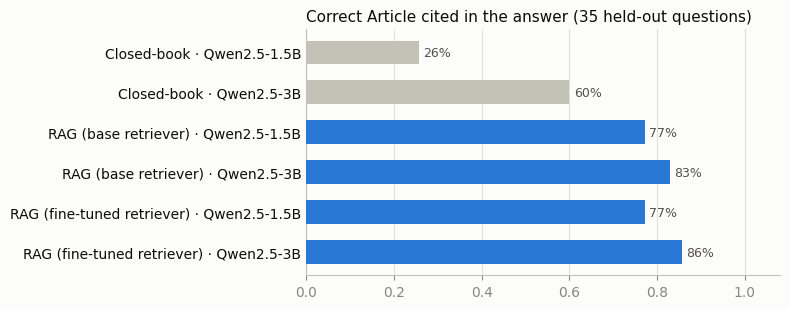

In [13]:
for gen in GENERATORS:
    E2E[f"RAG (fine-tuned retriever) · {gen}"] = run_end_to_end("ft", gen)
final_table = e2e_table(E2E)
display(final_table)

accuracy = pd.Series({label: df.correct.mean() for label, df in E2E.items()})
fig, ax = plt.subplots(figsize=(8, 3.2))
colours = ["#c3c2b7" if label.startswith("Closed") else BLUE for label in accuracy.index]
bars = ax.barh(accuracy.index[::-1], accuracy.values[::-1], color=colours[::-1], height=0.6, zorder=3)
for b, v in zip(bars, accuracy.values[::-1]):
    ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_xlim(0, 1.08)
style_axes(ax, "Correct Article cited in the answer (35 held-out questions)", grid_axis="x")
ax.tick_params(axis="y", length=0, colors="#0b0b0b")
plt.tight_layout()
plt.show()

## 11. Final System
Structure-aware chunking + fine-tuned retriever + `Qwen2.5-3B-Instruct`.

In [16]:
FINAL = {"retriever": "ft", "generator": "Qwen2.5-3B"}
article_meta = chunks_df.drop_duplicates("article").set_index("article")[["title", "part"]]

for q in ["Can the police arrest someone without telling them the reason?",
          "Can I go directly to the Supreme Court if my fundamental rights are violated?",
          "Who won the IPL in 2024?"]:
    r = answer(q, **FINAL)
    print(f"Q: {q}\nA: {r['answer']}")
    if r["articles"]:
        print("Sources: " + "; ".join(f"Article {a} – {article_meta.loc[a, 'title']}" if a != "Preamble"
                                      else "Preamble" for a in r["articles"]))
    print(f"[similarity {r['top']:.3f} · threshold {THRESHOLDS['ft']} · {'refused' if r['refused'] else 'answered'}]")
    print("─" * 100)

q = "Can the police arrest someone without telling them the reason?"
print(f"Closed-book ({FINAL['generator']}, no retrieval): {closed_book(q, FINAL['generator'], ask_for_article=False)}")

Q: Can the police arrest someone without telling them the reason?
A: No, the police cannot arrest someone without informing them of the reasons for the arrest as soon as possible [Article 22(1)].
Sources: Article 22 – Protection against arrest and detention in certain cases; Article 20 – Protection in respect of conviction for offences; Article 311 – Dismissal, removal or reduction in rank of persons employed in civil capacities under the Union or a State
[similarity 0.644 · threshold 0.48 · answered]
────────────────────────────────────────────────────────────────────────────────────────────────────
Q: Can I go directly to the Supreme Court if my fundamental rights are violated?
A: Yes, you can go directly to the Supreme Court if your fundamental rights are violated. [Article 32]. This article guarantees the right to move the Supreme Court by appropriate proceedings for the enforcement of the rights conferred by this Part.
Sources: Article 32 – Remedies for enforcement of rights confe

In [17]:
import gradio as gr


def respond(question: str, compare: bool):
    question = (question or "").strip()
    if not question:
        return "Please enter a question.", "", "", "", ""
    r = answer(question, **FINAL)
    sources = ""
    if r["articles"]:
        rows = "\n".join(f"| {'Preamble' if a == 'Preamble' else 'Article ' + a} | {article_meta.loc[a, 'title']} "
                         f"| {article_meta.loc[a, 'part']} |" for a in r["articles"])
        sources = "**Sources**\n\n| Source | Title | Part |\n|---|---|---|\n" + rows
    status = (f"Top similarity **{r['top']:.3f}** (threshold {THRESHOLDS['ft']}) · "
              f"{'refused' if r['refused'] else 'answered'} · {r['latency']:.2f} s")
    if r["unsupported"]:
        status += f" · ⚠ unsupported citation(s): {', '.join(r['unsupported'])}"
    closed = (f"**Closed-book LLM (no retrieval):**\n\n{closed_book(question, FINAL['generator'], False)}"
              if compare else "")
    context = r["context"] or "No context — the question was refused by the similarity guardrail."
    return f"### Answer\n{r['answer']}", sources, status, context, closed


with gr.Blocks(title="Samvidhan Saathi") as demo:
    gr.Markdown("# Samvidhan Saathi\nAsk a question about the Constitution of India. "
                "Answers come only from the retrieved constitutional text and cite the Articles used.")
    with gr.Row():
        question = gr.Textbox(label="Your question", scale=4,
                              placeholder="e.g. Can I be arrested without being told why?")
        ask = gr.Button("Ask", variant="primary", scale=1)
    compare = gr.Checkbox(label="Also show the closed-book answer (same LLM, no retrieval)", value=False)
    gr.Examples(["Can the police arrest someone without telling them the reason?",
                 "Is education a fundamental right for children?",
                 "Can I go directly to the Supreme Court if my fundamental rights are violated?",
                 "What does the Preamble say about the nature of India?",
                 "Who won the IPL in 2024?"], inputs=question)
    answer_md, sources_md, status_md, closed_md = gr.Markdown(), gr.Markdown(), gr.Markdown(), gr.Markdown()
    with gr.Accordion("Retrieved context passed to the LLM", open=False):
        context_box = gr.Textbox(lines=12, show_label=False, interactive=False)
    outputs = [answer_md, sources_md, status_md, context_box, closed_md]
    ask.click(respond, [question, compare], outputs)
    question.submit(respond, [question, compare], outputs)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6676d3b0fa5eb1f333.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 12. Conclusion
- **Structure-aware chunking** outperforms fixed-size chunking at the top ranks, which matter most for RAG, and enables Article-level citation.
- **Retrieval grounding** sharply raises citation accuracy over the same LLM answering closed-book, and the calibrated guardrail refuses off-topic questions without calling the LLM.
- **A larger generator** (3B vs 1.5B) converts retrieved evidence into correct citations more reliably.
- **Fine-tuning the retriever** on LLM-generated, leakage-filtered domain data improves held-out retrieval, fixing several vocabulary-mismatch and mirror-provision errors; some remain (e.g. *Lok Sabha* is still matched to the Panchayat provision, Article 243E).

**Limitations:** small evaluation set (35 questions); synthetic training data from a 1.5B model; the Schedules are not indexed; the citation check verifies that a cited Article was retrieved, not that it is the correct one.
**Future work:** hybrid BM25 + dense retrieval with a re-ranker, hard negatives from mirror provisions, and Hindi/Punjabi queries.

**References:** Lewis et al., *Retrieval-Augmented Generation*, NeurIPS 2020 · Vaswani et al., *Attention Is All You Need*, NeurIPS 2017 ·
Xiao et al., *C-Pack (BGE)*, arXiv:2309.07597 · Qwen Team, *Qwen2.5 Technical Report*, arXiv:2412.15115 ·
Johnson et al., *Billion-scale Similarity Search with GPUs*, IEEE TBD 2019.